# Deep Q-Network (DQN)
---
In this notebook, you will implement a DQN agent with OpenAI Gym's LunarLander-v2 environment.

### 1. Import the Necessary Packages

In [1]:
from unityagents import UnityEnvironment
import numpy as np

import random
import torch
from collections import deque
import matplotlib.pyplot as plt
%matplotlib inline

### 2. Instantiate the Environment and Agent

Initialize the environment in the code cell below.

In [ ]:
env = UnityEnvironment(file_name="~/Documents/RL/Udacity-RL/Banana.app")

# get the default brain
brain_name = env.brain_names[0]
brain = env.brains[brain_name]

In [3]:
# reset the environment
env_info = env.reset(train_mode=True)[brain_name]

# number of agents in the environment
print('Number of agents:', len(env_info.agents))

# number of actions
action_size = brain.vector_action_space_size
print('Number of actions:', action_size)

# examine the state space 
state = env_info.vector_observations[0]
print('States look like:', state)
state_size = len(state)
print('States have length:', state_size)

Number of agents: 1
Number of actions: 4
States look like: [1.         0.         0.         0.         0.84408134 0.
 0.         1.         0.         0.0748472  0.         1.
 0.         0.         0.25755    1.         0.         0.
 0.         0.74177343 0.         1.         0.         0.
 0.25854847 0.         0.         1.         0.         0.09355672
 0.         1.         0.         0.         0.31969345 0.
 0.        ]
States have length: 37


In [4]:
env_info = env.reset(train_mode=False)[brain_name] # reset the environment
state = env_info.vector_observations[0]            # get the current state
score = 0                                          # initialize the score
ts = 0
while True:
    action = np.random.randint(action_size)        # select an action
    env_info = env.step(action)[brain_name]        # send the action to the environment
    next_state = env_info.vector_observations[0]   # get the next state
    reward = env_info.rewards[0]                   # get the reward
    done = env_info.local_done[0]                  # see if episode has finished
    score += reward                                # update the score
    state = next_state                             # roll over the state to next time step
    ts+=1
    if done:                                       # exit loop if episode finished
        break
    
print("Score: {}, time steps: {}".format(score, ts))

Score: 0.0, time steps: 300


In [5]:
# env.close()

## 3. Train the Agent with DQN

Run the code cell below to train the agent from scratch.  

### 3.1 Diagnostics

Diagnostics of frozen policy evaluation during training

In [3]:
def diag(agent, env):
    '''
    Periodic diagnostic run code
    Params
    ======
        agent : trained agent
        env: Banana Collector environment
    '''
    GAMMA = 0.99
    
    env_info = env.reset(train_mode=False)[brain_name]
    total_reward, returns, successes, ep_len, final_reward, truncations = list(), list(), list(), list(), list(), list()
    for k in range(100):
        rewards = list()
        
        done = False
        env_info = env.reset(train_mode=False)[brain_name]
        state = env_info.vector_observations[0]
        while not done:
            action = agent.act(state)
            env_info = env.step(action)[brain_name]
            next_state = env_info.vector_observations[0]
            rewards.append(env_info.rewards[0])
            done = env_info.local_done[0]
            state = next_state
    
        final_reward.append(rewards[-1])
        total_reward.append(sum(rewards))
        l = len(rewards)
        weights = [GAMMA**i for i in range(l)]
        returns.append(sum([r*w for r, w in zip(rewards,weights)]) )
        ep_len.append(l)
        if k%10==0:
            print(f'End of episode. Return: {returns[-1]}')
    return {'mean_undiscounted_reward': np.mean(total_reward),
            'median_undiscounted_reward': np.median(total_reward),
            'mean_return': np.mean(returns), 
            'median_return': np.median(returns) , 
            'SD_return': np.std(returns), 
            'min_return':np.min(returns),
            'max_return':np.max(returns), 
            'mean_episode_len':np.mean(ep_len),
            'mean_final_reward': np.mean(final_reward),
            'success_rate': np.sum(successes),
            'truncation_rate': np.sum(truncations)}


### 4.2 Training with Optional Diagnostics

Episode 100	Average Score: 0.91
Created a checkpoint
Episode 200	Average Score: 3.25
Created a checkpoint
Episode 300	Average Score: 6.39
Created a checkpoint
Episode 400	Average Score: 9.04
Created a checkpoint
Episode 500	Average Score: 9.88
Created a checkpoint
Episode 600	Average Score: 11.29
Created a checkpoint
Episode 700	Average Score: 11.09
Episode 800	Average Score: 11.76
Created a checkpoint
Episode 900	Average Score: 12.98
Created a checkpoint
Episode 1000	Average Score: 12.43
Episode 1100	Average Score: 13.56
Created a checkpoint

Environment solved in 1000 episodes!	Average Score: 13.56


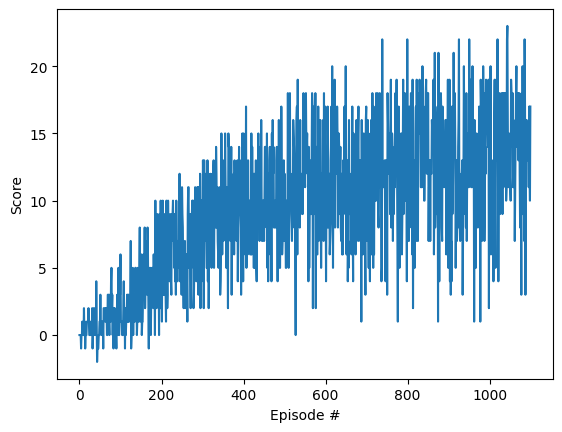

In [4]:
import math
from dqn_agent_slow_lr import Agent
def dqn_w_diag(n_episodes=2400, max_t=300, eps_start=1.0, eps_end=0.01, eps_decay=0.995):
    """Deep Q-Learning.
    
    Params
    ======
        n_episodes (int): maximum number of training episodes
        max_t (int): maximum number of timesteps per episode
        eps_start (float): starting value of epsilon, for epsilon-greedy action selection
        eps_end (float): minimum value of epsilon
        eps_decay (float): multiplicative factor (per episode) for decreasing epsilon
    """
    scores = []                        # list containing scores from each episode
    scores_window = deque(maxlen=100)  # last 100 scores
    eps = eps_start                    # initialize epsilon
    # g_best = -math.inf               # Frozen policy evaluation best return
    best_rolling_mean_score = -math.inf # Rolling average score over the last 100 training episodes
    agent = Agent(state_size=37, action_size=4, seed=0)
    
    eval_returns = list()
    for i_episode in range(1, n_episodes+1):
        env_info = env.reset(train_mode=True)[brain_name]
        state = env_info.vector_observations[0]
        score = 0
        # episode
        while True:
            action = agent.act(state, eps)
            env_info = env.step(action)[brain_name]
            next_state = env_info.vector_observations[0]
            reward = env_info.rewards[0]
            done = env_info.local_done[0]
            agent.step(state, action, reward, next_state, done)
            state = next_state
            score += reward
            if done:
                break 
        scores_window.append(score)       # save most recent score
        scores.append(score)              # save most recent score
        eps = max(eps_end, eps_decay*eps) # decrease epsilon
        print('\rEpisode {}\tAverage Score: {:.2f}'.format(i_episode, np.mean(scores_window)), end="")
        if i_episode % 100 == 0:
            print('\rEpisode {}\tAverage Score: {:.2f}'.format(i_episode, np.mean(scores_window)))
            if np.mean(scores_window) > best_rolling_mean_score:
                torch.save(agent.qnetwork_local.state_dict(), 'p1_checkpoint.pth')
                best_rolling_mean_score = np.mean(scores_window)
                print('Created a checkpoint')
            if best_rolling_mean_score >= 13.0:
                print('\nEnvironment solved in {:d} episodes!\tAverage Score: {:.2f}'.format(i_episode-100, np.mean(scores_window)))
                torch.save(agent.qnetwork_local.state_dict(), 'p1_checkpoint.pth')
                env.close()
                break
        '''
        ## Frozen policy evaluation
        if i_episode % 300 == 0:
            print('\rEpisode {}\tAverage Score: {:.2f}'.format(i_episode, np.mean(scores_window)))
            diags = diag(agent, env)
            print(f'diags:{diags}')
            
            eval_returns.append(diags['mean_undiscounted_reward'])
            if diags['mean_undiscounted_reward'] > g_best:
                torch.save(agent.qnetwork_local.state_dict(), 'checkpoint.pth')
                g_best = diags['mean_undiscounted_reward']
                print('Created a checkpoint')
        if len(eval_returns)>2 and (eval_returns[-1]>=13.0):
            print('\nEnvironment solved in {:d} episodes!\tAverage Score: {:.2f}'.format(i_episode-100, np.mean(scores_window)))
            torch.save(agent.qnetwork_local.state_dict(), 'checkpoint.pth')
            env.close()
            break
        '''
    #env.close()
    return scores

scores = dqn_w_diag()

# plot the scores
fig = plt.figure()
ax = fig.add_subplot(111)
plt.plot(np.arange(len(scores)), scores)
plt.ylabel('Score')
plt.xlabel('Episode #')
plt.show()

In [ ]:
env.close()

## 5. Watch a Smart Agent!

In the next code cell, you will load the trained weights from file to watch a smart agent!

In [ ]:
from dqn_agent_slow_lr import Agent
# load the weights from file
agent = Agent(state_size=37, action_size=4, seed=0)
agent.qnetwork_local.load_state_dict(torch.load('p1_checkpoint.pth'))
env = UnityEnvironment(file_name="./Banana.app")
# get the default brain
brain_name = env.brain_names[0]
brain = env.brains[brain_name]
episode_scores = []
score = 0
env_info = env.reset(train_mode=False)[brain_name]
for i in range(5):
    score = 0
    env_info = env.reset(train_mode=False)[brain_name]
    for j in range(300):
        state = env_info.vector_observations[0]
        action = agent.act(state)
        #env.render()
        env_info = env.step(action)[brain_name]
        reward = env_info.rewards[0]
        score += reward
        if env_info.local_done[0]:
            print(f'Episode: {i} episode score: {score}')
            break 
    print(f'Episode: {i} episode score: {score}')
            
env.close()